<a href="https://colab.research.google.com/github/Ambesh246/Prompt_Quality_Analyzer/blob/Colab-part/Prompt_Quality_Analyzer_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prompt Quality Analyzer — Machine Learning Project

**Goal:** take a prompt written by a user, estimate its quality on a 0–100 scale, point out possible gaps, and build a clearer version of the same request.

This notebook is written as a step-by-step student project: first understand the data, then explore it, build features, train a model, evaluate it, and finally use it on a new prompt.


## 1. Problem statement and approach

A prompt can be difficult to answer when the task is unclear, important context is missing, constraints are vague, or the expected response format is not stated. The analyzer tries to identify these signals before the prompt is used.

**ML framing:** supervised regression. Each training example contains prompt text and a normalized quality label. We train a model to predict that label.

**Hybrid design:** word TF-IDF captures terms and short phrases; character TF-IDF captures spelling and character patterns; hand-built structural features capture simple signals such as audience or requested format. Ridge regression combines these signals. A separate rule-based layer explains possible omissions.

**Dataset source:** [agentlans/prompt-quality on Hugging Face](https://huggingface.co/datasets/agentlans/prompt-quality). Its dataset page lists a CC BY 4.0 license and contains prompt text, normalized quality scores, and assessments from multiple models. We will keep the experiment small enough for a typical free Colab runtime.

## 2. Install and import libraries


In [1]:
!pip -q install datasets "scikit-learn==1.6.1" "numpy==2.1.3" "pandas==2.2.3" "joblib==1.5.2" ipywidgets


In [2]:
import re
import math
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from IPython.display import display, Markdown, clear_output
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Imports complete. Random state:", RANDOM_STATE)


Imports complete. Random state: 42


## 3. Load the public dataset



In [3]:
DATASET_ID = "agentlans/prompt-quality"
MAX_ROWS = 79800
hf_train = load_dataset(DATASET_ID, split="train")
required_columns = {"prompt", "transformed_quality"}
missing = required_columns - set(hf_train.column_names)
if missing:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing)}")

df = hf_train.select_columns(["prompt", "transformed_quality"]).to_pandas()
print("Loaded rows:", len(df))
print("Selected columns:", df.columns.tolist())
display(df.head())


README.md:   0%|          | 0.00/5.79k [00:00<?, ?B/s]

train.jsonl.zst: reconstructing file:   0%|          |  0.00B / 14.8MB            

train.jsonl.zst: downloading bytes:           |  0.00B            

test.jsonl.zst: reconstructing file:   0%|          |  0.00B / 3.78MB            

test.jsonl.zst: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/79806 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/19952 [00:00<?, ? examples/s]

Loaded rows: 79806
Selected columns: ['prompt', 'transformed_quality']


,prompt,transformed_quality
0,NAME_1 NAME_2 is the best anti virus for windows,0.00766
1,"Trace the evolution of children's books, exami...",0.71609
2,its the relation between my father and me is a...,0.02119
3,"[QUESTION] Given the sentence ""Two men in colo...",0.31654
4,"A car rental company has a fleet of 1,000 vehi...",0.92085


## 4. Select columns and clean the data

In [26]:
def normalize_prompt_key(value):
    text = re.sub(r"\s+", " ", str(value)).strip().lower()
    return text
df = df.dropna(subset=["prompt", "transformed_quality"]).copy()
df["prompt"] = df["prompt"].astype(str).str.strip()
df = df[df["prompt"].str.len() >= 2].copy()
df["transformed_quality"] = pd.to_numeric(
    df["transformed_quality"], errors="coerce"
)
df = df.dropna(subset=["transformed_quality"])
df["prompt_key"] = df["prompt"].map(normalize_prompt_key)

df = (
    df.groupby("prompt_key", as_index=False)
      .agg(prompt=("prompt", "first"), transformed_quality=("transformed_quality", "mean"))
)

if not df["transformed_quality"].between(0, 1).all():
    raise ValueError(
        "Expected transformed_quality labels between 0 and 1. "
        "Inspect the dataset label scale before continuing."
    )
df["target_score"] = df["transformed_quality"] * 100.0
if len(df) > MAX_ROWS:
    df = df.sample(n=MAX_ROWS, random_state=RANDOM_STATE)
df = df.reset_index(drop=True)
print("Rows after cleaning:", len(df))
print("Target scale:", round(df.target_score.min(), 2), "to", round(df.target_score.max(), 2))
print("Duplicate normalized prompts remaining:", int(df.prompt_key.duplicated().sum()))


Rows after cleaning: 79800
Target scale: 0.04 to 99.32
Duplicate normalized prompts remaining: 0


In [27]:
display(df[["prompt", "target_score"]].head())

,prompt,target_score
0,!!!!!!!!!!!!!Runtime Error!!!!!!!!!!!!!!!\nIn ...,3.164
1,"!ask from now on, you will give a detailed exp...",32.806
2,"!fix this code please!:\n\ntimes, err := cpu.T...",11.162
3,"!Given an array of string, that each string is...",18.424
4,"""\n* Periodic stimuli: These occur at predicta...",66.254


## 5. Explore the data (EDA)


In [5]:
df["word_count"] = df["prompt"].str.findall(r"\b\w+\b").str.len()

In [6]:
print("Prompt word-count summary:")
display(df["word_count"].describe().to_frame().T)

Prompt word-count summary:


,count,mean,std,min,25%,50%,75%,max
word_count,79800.0,106.422707,234.813569,1.0,14.0,39.0,95.0,6510.0


In [7]:
print("Target score summary:")
display(df["target_score"].describe().to_frame().T)


Target score summary:


,count,mean,std,min,25%,50%,75%,max
target_score,79800.0,52.194609,32.502732,0.043,20.2465,56.3655,83.754,99.317


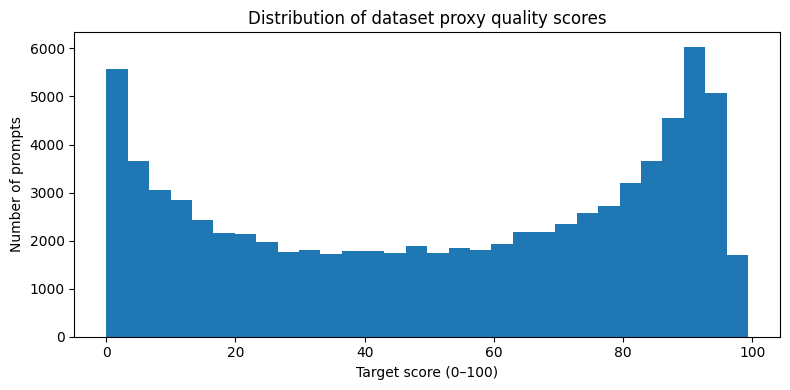

In [8]:
plt.figure(figsize=(8, 4))
plt.hist(df["target_score"], bins=30)
plt.title("Distribution of dataset proxy quality scores")
plt.xlabel("Target score (0–100)")
plt.ylabel("Number of prompts")
plt.tight_layout()
plt.show()

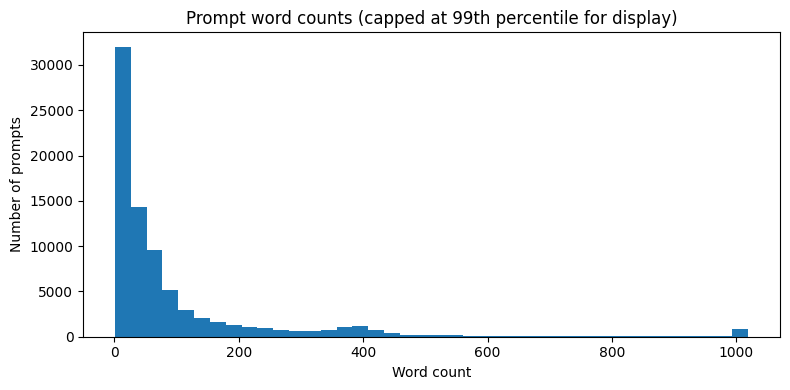

In [9]:
plt.figure(figsize=(8, 4))
plt.hist(df["word_count"].clip(upper=df["word_count"].quantile(0.99)), bins=40)
plt.title("Prompt word counts (capped at 99th percentile for display)")
plt.xlabel("Word count")
plt.ylabel("Number of prompts")
plt.tight_layout()
plt.show()

## 6. Create structural features

In [10]:
from pathlib import Path
import importlib, sys

CORE_SOURCE = '"""Stable shared functions for Prompt Quality Analyzer.\n\nKeep this module next to app.py before loading the exported joblib model.\nThe fitted sklearn pipeline references extract_structural_features by module path.\n"""\nimport re\nimport numpy as np\n\ndef contains_phrase(text, phrase):\n    """Match a phrase with word boundaries; allow flexible whitespace between words."""\n    text = str(text).lower()\n    phrase = str(phrase).lower().strip()\n    escaped = re.escape(phrase).replace(r"\\ ", r"\\s+")\n    pattern = r"(?<!\\w)" + escaped + r"(?!\\w)"\n    return re.search(pattern, text) is not None\n\n\ndef contains_any(text, phrases):\n    return int(any(contains_phrase(text, phrase) for phrase in phrases))\n\n\nFEATURE_PHRASES = {\n    "action_verb": ["explain", "summarize", "summarise", "translate", "write", "create", "build", "debug", "compare", "analyze", "analyse", "classify", "calculate", "design", "generate", "recommend", "plan", "extract", "evaluate", "review", "rewrite", "convert", "solve", "describe", "list", "draft", "what is", "what are", "who is", "who was", "why", "how do", "how does", "how to", "tell me", "give me", "can you", "help me", "find out"],\n    "context": ["context", "background", "given", "based on", "following", "here is", "scenario", "for this task", "the problem is"],\n    "audience": ["audience", "for beginners", "for a beginner", "for students", "for a student", "for experts", "for developers", "target reader", "second-year", "second year", "non-technical audience"],\n    "format": ["output format", "table", "bullet points", "json", "markdown", "headings", "numbered steps", "numbered list", "csv", "code block", "paragraphs", "checklist"],\n    "constraints": ["must", "should", "do not", "don\'t", "avoid", "limit", "maximum", "minimum", "exactly", "under", "at most", "no more than", "within", "word limit", "less than"],\n    "examples": ["example", "examples", "sample", "test case", "test cases", "worked example", "illustration"],\n    "success_criteria": ["success criteria", "acceptance criteria", "expected result", "expected output", "verify", "validate", "check correctness", "definition of done", "quality criteria", "evaluate against"],\n    "role": ["act as", "you are a", "as an expert", "as a professional", "role-play as"],\n    "input_data": ["input", "input data", "provided code", "following code", "dataset", "csv file", "document", "passage", "text:", "data:", "attached file", "below"],\n    "programming_language": ["python", "javascript", "typescript", "java", "c++", "c#", "sql", "bash", "go", "rust", "r language", "pseudocode"],\n    "expected_behavior": ["expected output", "should return", "must return", "return a", "output should", "expected behavior", "expected behaviour", "desired result"],\n    "tests": ["test", "tests", "unit test", "test case", "edge case", "assert"],\n    "edge_cases": ["edge case", "empty input", "invalid input", "error handling", "boundary condition", "missing values", "exceptions"],\n    "tone": ["tone", "formal", "friendly", "professional", "persuasive", "humorous", "conversational", "academic", "casual", "empathetic"],\n    "length": ["word limit", "words", "paragraphs", "concise", "brief", "under 500", "under 200", "length", "maximum length"],\n    "purpose": ["purpose", "objective", "aim", "intended to", "to persuade", "to inform", "to explain", "to announce"],\n    "required_content": ["include", "cover", "mention", "must include", "address", "discuss", "compare", "summarize", "summarise"],\n    "target_language": ["target language", "into english", "into spanish", "into hindi", "into french", "into german", "into bengali", "to english", "to spanish", "to hindi", "to french", "to german", "to bengali"],\n    "preserve_format": ["preserve formatting", "keep formatting", "maintain line breaks", "preserve tone", "keep the original format", "preserve the original meaning"],\n    "scope": ["scope", "focus on", "between", "from 2020", "from 2021", "as of", "in the last", "region", "country", "time period", "timeframe"],\n    "sources": ["cite sources", "sources", "references", "evidence", "peer-reviewed", "primary sources", "citations", "cite your sources"],\n    "methodology": ["methodology", "method", "research design", "systematic review", "compare approaches", "criteria", "analyze the data", "analyse the data"],\n    "uncertainty": ["assumptions", "limitations", "uncertainty", "caveats", "bias", "state assumptions", "if unsure"],\n    "metrics": ["metric", "metrics", "accuracy", "precision", "recall", "f1", "rmse", "mae", "r2", "r-squared"],\n    "validation": ["validate", "validation", "test set", "cross-validation", "sanity check", "verify", "quality check"]\n}\n\n\ndef extract_structural_features(texts):\n    rows = []\n    for value in texts:\n        text = str(value)\n        lower = text.lower()\n        words = re.findall(r"\\b[\\w\'-]+\\b", lower)\n        word_count = len(words)\n        char_count = len(text)\n        sentences = [part for part in re.split(r"[.!?]+", text) if part.strip()]\n        unique_ratio = len(set(words)) / max(word_count, 1)\n        avg_word_len = float(np.mean([len(w) for w in words])) if words else 0.0\n        digit_ratio = sum(ch.isdigit() for ch in text) / max(char_count, 1)\n        punctuation_ratio = sum(ch in r"!#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~" for ch in text) / max(char_count, 1)\n        list_markers = int(bool(re.search(r"(?m)^\\s*(?:[-*•]|\\d+[.)])\\s+", text)))\n        signal_values = [contains_any(lower, FEATURE_PHRASES[k]) for k in FEATURE_PHRASES]\n        rows.append([\n            np.log1p(char_count), np.log1p(word_count), avg_word_len,\n            unique_ratio, np.log1p(len(sentences)), np.log1p(text.count("?")),\n            np.log1p(text.count("!")), np.log1p(text.count("\\n")),\n            digit_ratio, punctuation_ratio, list_markers,\n            *signal_values\n        ])\n    return np.asarray(rows, dtype=float)\n\n\n# Each task has its own checklist. Weights add to 100 for each task type.\nRUBRICS = {\n    "general": [\n        ("task", "A clear action/task is identifiable", 20, ["explain", "summarize", "summarise", "write", "create", "compare", "analyze", "analyse", "translate", "debug", "calculate", "design", "generate", "recommend", "plan", "solve", "describe", "review", "draft", "list", "what is", "what are", "who is", "who was", "why", "how do", "how does", "how to", "tell me", "give me", "can you", "help me", "find out"]),\n        ("context", "Relevant context/input is supplied", 15, FEATURE_PHRASES["context"] + ["text:", "data:", "code:"]),\n        ("audience", "Audience or knowledge level is specified", 10, FEATURE_PHRASES["audience"]),\n        ("format", "Desired output format is clear", 15, FEATURE_PHRASES["format"]),\n        ("constraints", "Important constraints/requirements are stated", 15, FEATURE_PHRASES["constraints"]),\n        ("examples", "Examples or samples are requested/provided when useful", 10, FEATURE_PHRASES["examples"]),\n        ("success", "Success/verification criteria are stated", 15, FEATURE_PHRASES["success_criteria"]),\n    ],\n    "coding": [\n        ("task", "Programming task is identifiable", 15, FEATURE_PHRASES["action_verb"]),\n        ("language", "Programming language is specified", 15, FEATURE_PHRASES["programming_language"]),\n        ("input", "Input, code, or problem details are provided", 15, FEATURE_PHRASES["input_data"] + ["function:", "bug:", "error:"]),\n        ("behavior", "Expected behavior/output is stated", 15, FEATURE_PHRASES["expected_behavior"]),\n        ("edges", "Edge cases or error handling are mentioned", 10, FEATURE_PHRASES["edge_cases"]),\n        ("tests", "Tests or test cases are requested", 10, FEATURE_PHRASES["tests"]),\n        ("constraints", "Constraints are included", 10, FEATURE_PHRASES["constraints"]),\n        ("format", "Code/explanation output format is described", 10, FEATURE_PHRASES["format"] + ["provide code", "explain the code"]),\n    ],\n    "education": [\n        ("task", "Learning task/topic is identifiable", 20, FEATURE_PHRASES["action_verb"]),\n        ("audience", "Learner level/audience is specified", 20, FEATURE_PHRASES["audience"] + ["school student", "college student", "second year", "beginner level"]),\n        ("context", "Topic or learning context is indicated", 10, FEATURE_PHRASES["context"] + ["topic", "chapter", "subject"]),\n        ("examples", "Examples or worked examples are requested", 15, FEATURE_PHRASES["examples"]),\n        ("format", "Teaching/output structure is specified", 10, FEATURE_PHRASES["format"] + ["step by step", "step-by-step"]),\n        ("constraints", "Depth, length, or scope constraints are present", 10, FEATURE_PHRASES["constraints"] + FEATURE_PHRASES["length"]),\n        ("success", "Practice/check-understanding criteria are included", 15, FEATURE_PHRASES["success_criteria"] + ["quiz", "practice questions", "check my understanding"]),\n    ],\n    "writing": [\n        ("task", "Writing purpose/task is identifiable", 20, FEATURE_PHRASES["action_verb"] + FEATURE_PHRASES["purpose"]),\n        ("audience", "Intended audience is specified", 15, FEATURE_PHRASES["audience"]),\n        ("tone", "Tone or voice is specified", 10, FEATURE_PHRASES["tone"]),\n        ("format", "Output format is specified", 10, FEATURE_PHRASES["format"]),\n        ("length", "Length or size is specified", 10, FEATURE_PHRASES["length"] + FEATURE_PHRASES["constraints"]),\n        ("content", "Required content is listed", 15, FEATURE_PHRASES["required_content"]),\n        ("examples", "Style/sample reference is provided when helpful", 10, FEATURE_PHRASES["examples"] + ["in the style of", "match this style"]),\n        ("constraints", "Other important constraints are stated", 10, FEATURE_PHRASES["constraints"]),\n    ],\n    "research": [\n        ("task", "Research question/objective is identifiable", 15, FEATURE_PHRASES["action_verb"] + FEATURE_PHRASES["purpose"]),\n        ("scope", "Scope, timeframe, population, or geography is defined", 15, FEATURE_PHRASES["scope"]),\n        ("sources", "Evidence/source requirements are specified", 20, FEATURE_PHRASES["sources"]),\n        ("method", "Method or comparison approach is described", 15, FEATURE_PHRASES["methodology"]),\n        ("format", "Expected report structure is specified", 10, FEATURE_PHRASES["format"]),\n        ("constraints", "Research constraints are included", 10, FEATURE_PHRASES["constraints"]),\n        ("uncertainty", "Limitations, assumptions, or uncertainty are requested", 15, FEATURE_PHRASES["uncertainty"]),\n    ],\n    "data_analysis": [\n        ("task", "Analysis objective is identifiable", 15, FEATURE_PHRASES["action_verb"] + FEATURE_PHRASES["purpose"]),\n        ("data", "Dataset/input details are provided", 20, FEATURE_PHRASES["input_data"] + FEATURE_PHRASES["metrics"] + ["columns", "rows", "spreadsheet"]),\n        ("metrics", "Variables or metrics are named", 15, FEATURE_PHRASES["metrics"]),\n        ("assumptions", "Assumptions/constraints are addressed", 10, FEATURE_PHRASES["uncertainty"] + FEATURE_PHRASES["constraints"]),\n        ("format", "Desired output/visualization format is specified", 10, FEATURE_PHRASES["format"] + ["chart", "plot", "graph", "dashboard"]),\n        ("validation", "Validation or quality checks are requested", 15, FEATURE_PHRASES["validation"] + FEATURE_PHRASES["success_criteria"]),\n        ("audience", "Audience/context is specified", 5, FEATURE_PHRASES["audience"]),\n        ("scope", "Analysis scope is clear", 10, FEATURE_PHRASES["scope"] + ["focus on", "compare groups"]),\n    ],\n    "translation": [\n        ("task", "Translation request is identifiable", 20, ["translate", "translation", "render in", "convert into"]),\n        ("source", "Source text appears to be provided", 25, ["text:", "passage:", "translate", "following text", "quoted text"]),\n        ("language", "Target language is specified", 25, FEATURE_PHRASES["target_language"] + ["into italian", "into portuguese", "into japanese", "into korean", "into arabic", "into urdu", "into marathi", "into tamil", "into telugu", "into gujarati", "into punjabi", "into chinese", "into russian"]),\n        ("context", "Context or audience is specified when nuance matters", 10, FEATURE_PHRASES["context"] + FEATURE_PHRASES["audience"]),\n        ("tone", "Tone/register requirements are specified", 10, FEATURE_PHRASES["tone"] + ["formal register", "informal register", "polite form"]),\n        ("format", "Formatting/meaning preservation is specified", 5, FEATURE_PHRASES["preserve_format"] + FEATURE_PHRASES["format"]),\n        ("constraints", "Translation constraints are specified", 5, FEATURE_PHRASES["constraints"]),\n    ]\n}\n\nassert all(sum(row[2] for row in rows) == 100 for rows in RUBRICS.values())\n\n\nSUGGESTIONS = {\n    "task": "State the exact action and the result you want.",\n    "context": "Add the relevant background, input, or situation; avoid making the reader guess essential details.",\n    "audience": "Specify who the answer is for and the expected knowledge level, if that affects the answer.",\n    "format": "Specify the preferred output format, such as steps, a table, bullets, code, or a short report.",\n    "constraints": "Add relevant limits or requirements (for example, length, tools, scope, or things to avoid).",\n    "examples": "Add an example or sample input/output if it would clarify what a good result looks like.",\n    "success": "Define what a satisfactory answer should contain and how it should be checked.",\n    "language": "Specify the programming language and, if relevant, its version or runtime.",\n    "input": "Provide the relevant code/data/input and include any error message or sample where applicable.",\n    "behavior": "Describe expected behaviour and output, including how success should look.",\n    "edges": "Mention important edge cases, invalid inputs, and expected error handling.",\n    "tests": "Ask for test cases covering normal and edge-case inputs.",\n    "tone": "Specify the desired tone or voice.",\n    "length": "Set a suitable length or level of detail.",\n    "content": "List the key points or content that must be included.",\n    "scope": "Bound the scope, timeframe, population, or geographical context.",\n    "sources": "Specify acceptable evidence or source requirements and whether citations are needed.",\n    "method": "State the analysis or comparison method, or ask the assistant to explain its method.",\n    "uncertainty": "Ask the answer to state assumptions, limitations, and uncertainty rather than inventing facts.",\n    "data": "Specify the dataset, columns, units, missing-value rules, or input files.",\n    "metrics": "Name the outcome metrics or variables to analyze.",\n    "assumptions": "State assumptions explicitly and explain how conclusions depend on them.",\n    "validation": "Ask for sanity checks, validation steps, or a way to verify the result.",\n    "source": "Clearly separate the source text from the instructions.",\n    "format_preserve": "State whether original formatting, tone, and meaning must be preserved."\n}\n\n\ndef get_suggestion(key, task_type):\n    if task_type == "translation" and key == "language":\n        return "Specify the target language (for example, Spanish, Hindi, or French)."\n    if task_type == "translation" and key == "source":\n        return "Clearly delimit the source text to translate, for example with quotation marks or a \'Text:\' label."\n    if task_type == "research" and key == "sources":\n        return "Specify the evidence standard and whether citations or primary sources are required."\n    if task_type == "coding" and key == "language":\n        return "Specify the programming language and, if relevant, its version/runtime."\n    return SUGGESTIONS.get(key, f"Review this dimension if it is relevant: {key}.")\n\n\ndef detect_criteria(prompt, task_type="general"):\n    text = str(prompt).strip()\n    normalized = re.sub(r"\\s+", " ", text.lower())\n    results = []\n    for key, label, weight, phrases in RUBRICS[task_type]:\n        detected = contains_any(normalized, phrases)\n        # Translation source signal: quotes or text delimiter help; otherwise use a basic length check.\n        if task_type == "translation" and key == "source":\n            has_delimited_text = bool(re.search(r"""\'[^\']+\'|"[^"]+"|(?:text|passage)\\s*:""", text, flags=re.I | re.S))\n            detected = detected and (has_delimited_text or len(re.findall(r"\\b\\w+\\b", text)) >= 4)\n        results.append({"key": key, "dimension": label, "weight": weight, "detected": bool(detected)})\n    return results\n\n\ndef rubric_score(criteria_results):\n    return float(sum(row["weight"] for row in criteria_results if row["detected"]))\n\n\ndef build_improved_prompt(prompt, task_type, criteria_results):\n    original = str(prompt).strip()\n    missing = sorted([row for row in criteria_results if not row["detected"]], key=lambda row: row["weight"], reverse=True)\n    # Choose a concise task-specific skeleton that preserves the original request.\n    if task_type == "coding":\n        template = [\n            "Original task (preserve its intent):",\n            original,\n            "\\nInstructions:",\n            "- Use the programming language/runtime specified in the original request; if missing and essential, ask or clearly state an assumption.",\n            "- Explain the expected behaviour and provide a practical solution.",\n            "- Cover relevant edge cases and error handling; include tests where useful.",\n            "- Keep the response organized and avoid changing the requested functionality.",\n        ]\n    elif task_type == "education":\n        template = [\n            "Original learning request (preserve its intent):",\n            original,\n            "\\nTeaching guidance:",\n            "- Match the explanation to the audience and level stated in the original request; if unspecified, use a beginner-friendly level and say so.",\n            "- Explain key ideas clearly, define necessary technical terms, and use a relevant example when it helps.",\n            "- Organize the answer with clear sections and a short recap; do not add unrelated material.",\n        ]\n    elif task_type == "writing":\n        template = [\n            "Original writing task (preserve its intent):",\n            original,\n            "\\nWriting guidance:",\n            "- Follow any audience, tone, format, and length specified in the original request.",\n            "- If an important writing preference is missing, make a reasonable minimal assumption or ask a concise question.",\n            "- Include the requested key content, avoid unrelated additions, and produce a polished final draft.",\n        ]\n    elif task_type == "research":\n        template = [\n            "Original research request (preserve its intent):",\n            original,\n            "\\nResearch guidance:",\n            "- Clarify the scope and timeframe when they materially affect the answer.",\n            "- Support factual claims with reliable sources when available; do not fabricate citations.",\n            "- Separate evidence from inference, explain the method or comparison criteria, and state uncertainty and limitations.",\n            "- Organize findings with a concise conclusion and relevant caveats.",\n        ]\n    elif task_type == "data_analysis":\n        template = [\n            "Original data-analysis request (preserve its intent):",\n            original,\n            "\\nAnalysis guidance:",\n            "- Identify the data/input, analytical goal, relevant variables, and evaluation metrics.",\n            "- State assumptions, units, missing-data handling, and limitations where relevant.",\n            "- Use appropriate tables or visualizations, validate results, and distinguish observed results from interpretation.",\n        ]\n    elif task_type == "translation":\n        template = [\n            "Original translation request (preserve its intent):",\n            original,\n            "\\nTranslation guidance:",\n            "- Preserve the source meaning; do not add information that is not in the source.",\n            "- Use the target language named in the original request. If it is missing or ambiguous, ask for clarification.",\n            "- Preserve tone and formatting where appropriate; explain an ambiguity briefly rather than guessing if it changes the meaning.",\n        ]\n    else:\n        template = [\n            "Original request (preserve its intent):",\n            original,\n            "\\nResponse guidance:",\n            "- Answer the original task directly and use only relevant context; do not expand the task unnecessarily.",\n            "- Follow any audience, constraints, and output format already specified in the original request.",\n            "- If an essential detail is missing, ask a concise clarifying question or state a reasonable assumption.",\n            "- Organize the response clearly and distinguish facts from assumptions or uncertainty.",\n        ]\n    # Add no more than three highly relevant diagnostic reminders. The guidance remains generic by design.\n    if missing:\n        reminders = []\n        for item in missing:\n            suggestion = get_suggestion(item["key"], task_type)\n            if suggestion and suggestion not in reminders:\n                reminders.append(suggestion)\n            if len(reminders) == 3:\n                break\n        if reminders:\n            template.extend(["\\nPotential details to clarify (only if relevant):"])\n            template.extend([f"- {item}" for item in reminders])\n    template.append("\\nKeep the user\'s original objective unchanged. Do not invent missing facts or impose unnecessary requirements.")\n    return "\\n".join(template)\n\n\ndef score_band(score):\n    # Illustrative display bands; they are not validated universal standards.\n    if score < 40:\n        return "Needs improvement"\n    if score < 65:\n        return "Developing"\n    if score < 85:\n        return "Good foundation"\n    return "Strong prompt structure"\n\n\n__all__ = [\n    "FEATURE_PHRASES", "contains_phrase", "contains_any",\n    "extract_structural_features", "RUBRICS", "SUGGESTIONS",\n    "get_suggestion", "detect_criteria", "rubric_score",\n    "build_improved_prompt", "score_band",\n]\n'
Path("prompt_quality_core.py").write_text(CORE_SOURCE, encoding="utf-8")
importlib.invalidate_caches()
sys.modules.pop("prompt_quality_core", None)
from prompt_quality_core import (
    FEATURE_PHRASES, contains_phrase, contains_any, extract_structural_features,
    RUBRICS, SUGGESTIONS, get_suggestion, detect_criteria, rubric_score,
    build_improved_prompt, score_band,
)
print("Shared prompt-analysis module ready.")
print("Structural numeric feature count:", len(extract_structural_features(["Explain machine learning."])[0]))


Shared prompt-analysis module ready.
Structural numeric feature count: 36


## 7. Train/test split


In [11]:
df["score_bin"] = pd.qcut(df["target_score"], q=10, labels=False, duplicates="drop")
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=RANDOM_STATE, stratify=df["score_bin"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=RANDOM_STATE, stratify=temp_df["score_bin"]
)

X_train = train_df["prompt"].to_numpy()
y_train = train_df["target_score"].to_numpy(dtype=float)
X_val = val_df["prompt"].to_numpy()
y_val = val_df["target_score"].to_numpy(dtype=float)
X_test = test_df["prompt"].to_numpy()
y_test = test_df["target_score"].to_numpy(dtype=float)

print(f"Train: {len(X_train):,} | Validation: {len(X_val):,} | Test: {len(X_test):,}")


Train: 55,860 | Validation: 11,970 | Test: 11,970


## 8. Establish a simple baseline

A useful model should beat a simple baseline. Here the baseline always predicts the mean quality label from the training data. Later we compare the ML model against it using MAE, RMSE, and R².

In [12]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(np.zeros((len(y_train), 1)), y_train)
val_baseline_predictions = baseline.predict(np.zeros((len(y_val), 1)))

print("Validation baseline")
print(f"MAE:  {mean_absolute_error(y_val, val_baseline_predictions):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_val, val_baseline_predictions)):.2f}")
print(f"R²:   {r2_score(y_val, val_baseline_predictions):.3f}")


Validation baseline
MAE:  29.16
RMSE: 32.53
R²:   -0.000


## 9. Build the ML model

The model combines three feature groups:

- **Word TF-IDF:** informative words and two-word phrases.
- **Character TF-IDF:** spelling and character-pattern information.
- **Structural features:** readable signals we engineered in the earlier cell.

Ridge regression is a regularized linear model. It is a practical first choice for sparse text features because it is comparatively fast and keeps the pipeline easy to inspect. This is not a fine-tuned large language model.

In [13]:
def make_model(include_chars=True, include_structural=True, alpha=2.0):
    feature_blocks = [
        ("word_tfidf", TfidfVectorizer(
            analyzer="word", ngram_range=(1, 2), max_features=10000,
            min_df=2, sublinear_tf=True, strip_accents="unicode"
        ))
    ]
    if include_chars:
        feature_blocks.append((
            "char_tfidf", TfidfVectorizer(
                analyzer="char", ngram_range=(3, 5), max_features=5000,
                min_df=3, sublinear_tf=True
            )
        ))
    if include_structural:
        feature_blocks.append((
            "structural", Pipeline([
                ("extract", FunctionTransformer(extract_structural_features, validate=False)),
                ("scale", StandardScaler(with_mean=False))
            ])
        ))
    return Pipeline([
        ("features", FeatureUnion(feature_blocks)),
        ("regressor", Ridge(alpha=alpha))
    ])


def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

candidate_specs = {
    "Word TF-IDF": {"include_chars": False, "include_structural": False},
    "Word + Character TF-IDF": {"include_chars": True, "include_structural": False},
    "Hybrid (Word + Character + Structure)": {"include_chars": True, "include_structural": True},
}

validation_rows = []
fitted_candidates = {}
for name, config in candidate_specs.items():
    candidate = make_model(**config, alpha=2.0)
    candidate.fit(X_train, y_train)
    pred = candidate.predict(X_val)
    metrics = regression_metrics(y_val, pred)
    validation_rows.append({"Configuration": name, **metrics})
    fitted_candidates[name] = candidate

baseline_val = DummyRegressor(strategy="mean")
baseline_val.fit(X_train.reshape(-1, 1), y_train)
baseline_pred = baseline_val.predict(np.zeros((len(X_val), 1)))
validation_rows.append({"Configuration": "Mean baseline", **regression_metrics(y_val, baseline_pred)})

validation_results = pd.DataFrame(validation_rows).sort_values("MAE")
display(validation_results.round(4))
best_name = min(
    [name for name in candidate_specs],
    key=lambda name: regression_metrics(y_val, fitted_candidates[name].predict(X_val))["MAE"]
)
print("Selected on validation MAE:", best_name)


,Configuration,MAE,RMSE,R2
2,Hybrid (Word + Character + Structure),18.2674,22.8558,0.5063
1,Word + Character TF-IDF,18.7625,23.3884,0.4830
0,Word TF-IDF,19.6365,24.2660,0.4435
3,Mean baseline,29.1646,32.5282,-0.0000


Selected on validation MAE: Hybrid (Word + Character + Structure)


## 10. Evaluate on the held-out test set

- **MAE:** average absolute prediction error in score points. Lower is better.
- **RMSE:** like MAE, but penalizes larger errors more. Lower is better.
- **R²:** compares the model with a constant-mean prediction. Higher is better; it can be negative if the model is worse than that baseline.

Report the actual values produced by your run. Do not put a made-up accuracy number in the evaluation.

In [14]:
trainval_df = pd.concat([train_df, val_df], axis=0).copy()
X_trainval = trainval_df["prompt"].to_numpy()
y_trainval = trainval_df["target_score"].to_numpy(dtype=float)

selected_config = candidate_specs[best_name]
prompt_model = make_model(**selected_config, alpha=2.0)
prompt_model.fit(X_trainval, y_trainval)

baseline_final = DummyRegressor(strategy="mean")
baseline_final.fit(X_trainval.reshape(-1, 1), y_trainval)
baseline_test_pred = baseline_final.predict(np.zeros((len(X_test), 1)))
raw_test_pred = prompt_model.predict(X_test)
clipped_test_pred = np.clip(raw_test_pred, 0, 100)

final_results = pd.DataFrame([
    {"Prediction method": "Mean baseline", **regression_metrics(y_test, baseline_test_pred)},
    {"Prediction method": "Selected model (raw)", **regression_metrics(y_test, raw_test_pred)},
    {"Prediction method": "Selected model (clipped for display)", **regression_metrics(y_test, clipped_test_pred)},
])
display(final_results.round(4))

out_of_range = int(((raw_test_pred < 0) | (raw_test_pred > 100)).sum())
print(f"Raw predictions outside 0–100 display scale: {out_of_range:,}/{len(raw_test_pred):,}")
print("Remember: R² is not classification accuracy or a probability.")


,Prediction method,MAE,RMSE,R2
0,Mean baseline,29.1924,32.5249,-0.0000
1,Selected model (raw),18.1744,22.6816,0.5137
2,Selected model (clipped for display),17.9771,22.5826,0.5179


Raw predictions outside 0–100 display scale: 333/11,970
Remember: R² is not classification accuracy or a probability.


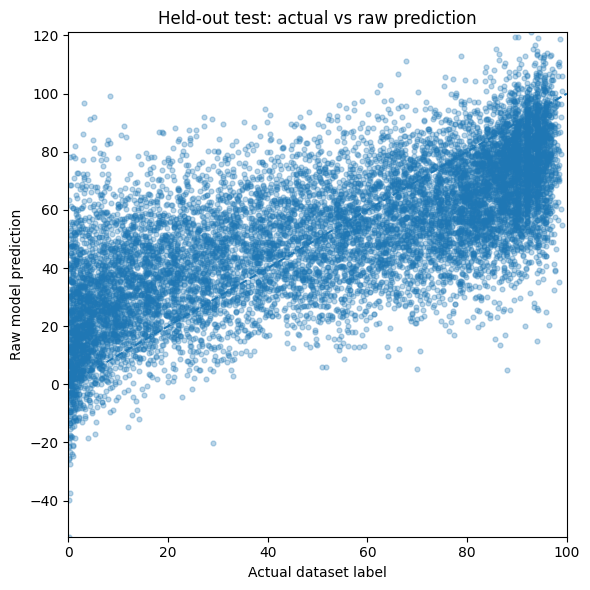

In [15]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, raw_test_pred, alpha=0.3, s=12)
plt.plot([0, 100], [0, 100], linestyle="--")
plt.xlim(0, 100)
plt.ylim(min(-5, raw_test_pred.min()), max(105, raw_test_pred.max()))
plt.xlabel("Actual dataset label")
plt.ylabel("Raw model prediction")
plt.title("Held-out test: actual vs raw prediction")
plt.tight_layout()
plt.show()


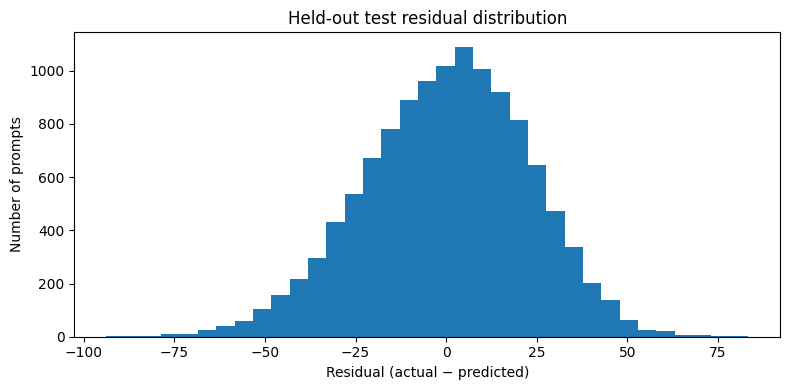

In [16]:
residuals = y_test - raw_test_pred
plt.figure(figsize=(8, 4))
plt.hist(residuals, bins=35)
plt.xlabel("Residual (actual − predicted)")
plt.ylabel("Number of prompts")
plt.title("Held-out test residual distribution")
plt.tight_layout()
plt.show()

## 11. Build explainable prompt checks


In [17]:
RUBRICS = {
    "general": [
        ("task", "A clear action/task is identifiable", 20, ["explain", "summarize", "summarise", "write", "create", "compare", "analyze", "analyse", "translate", "debug", "calculate", "design", "generate", "recommend", "plan", "solve", "describe", "review", "draft", "list", "what is", "what are", "who is", "who was", "why", "how do", "how does", "how to", "tell me", "give me", "can you", "help me", "find out"]),
        ("context", "Relevant context/input is supplied", 15, FEATURE_PHRASES["context"] + ["text:", "data:", "code:"]),
        ("audience", "Audience or knowledge level is specified", 10, FEATURE_PHRASES["audience"]),
        ("format", "Desired output format is clear", 15, FEATURE_PHRASES["format"]),
        ("constraints", "Important constraints/requirements are stated", 15, FEATURE_PHRASES["constraints"]),
        ("examples", "Examples or samples are requested/provided when useful", 10, FEATURE_PHRASES["examples"]),
        ("success", "Success/verification criteria are stated", 15, FEATURE_PHRASES["success_criteria"]),
    ],
    "coding": [
        ("task", "Programming task is identifiable", 15, FEATURE_PHRASES["action_verb"]),
        ("language", "Programming language is specified", 15, FEATURE_PHRASES["programming_language"]),
        ("input", "Input, code, or problem details are provided", 15, FEATURE_PHRASES["input_data"] + ["function:", "bug:", "error:"]),
        ("behavior", "Expected behavior/output is stated", 15, FEATURE_PHRASES["expected_behavior"]),
        ("edges", "Edge cases or error handling are mentioned", 10, FEATURE_PHRASES["edge_cases"]),
        ("tests", "Tests or test cases are requested", 10, FEATURE_PHRASES["tests"]),
        ("constraints", "Constraints are included", 10, FEATURE_PHRASES["constraints"]),
        ("format", "Code/explanation output format is described", 10, FEATURE_PHRASES["format"] + ["provide code", "explain the code"]),
    ],
    "education": [
        ("task", "Learning task/topic is identifiable", 20, FEATURE_PHRASES["action_verb"]),
        ("audience", "Learner level/audience is specified", 20, FEATURE_PHRASES["audience"] + ["school student", "college student", "second year", "beginner level"]),
        ("context", "Topic or learning context is indicated", 10, FEATURE_PHRASES["context"] + ["topic", "chapter", "subject"]),
        ("examples", "Examples or worked examples are requested", 15, FEATURE_PHRASES["examples"]),
        ("format", "Teaching/output structure is specified", 10, FEATURE_PHRASES["format"] + ["step by step", "step-by-step"]),
        ("constraints", "Depth, length, or scope constraints are present", 10, FEATURE_PHRASES["constraints"] + FEATURE_PHRASES["length"]),
        ("success", "Practice/check-understanding criteria are included", 15, FEATURE_PHRASES["success_criteria"] + ["quiz", "practice questions", "check my understanding"]),
    ],
    "writing": [
        ("task", "Writing purpose/task is identifiable", 20, FEATURE_PHRASES["action_verb"] + FEATURE_PHRASES["purpose"]),
        ("audience", "Intended audience is specified", 15, FEATURE_PHRASES["audience"]),
        ("tone", "Tone or voice is specified", 10, FEATURE_PHRASES["tone"]),
        ("format", "Output format is specified", 10, FEATURE_PHRASES["format"]),
        ("length", "Length or size is specified", 10, FEATURE_PHRASES["length"] + FEATURE_PHRASES["constraints"]),
        ("content", "Required content is listed", 15, FEATURE_PHRASES["required_content"]),
        ("examples", "Style/sample reference is provided when helpful", 10, FEATURE_PHRASES["examples"] + ["in the style of", "match this style"]),
        ("constraints", "Other important constraints are stated", 10, FEATURE_PHRASES["constraints"]),
    ],
    "research": [
        ("task", "Research question/objective is identifiable", 15, FEATURE_PHRASES["action_verb"] + FEATURE_PHRASES["purpose"]),
        ("scope", "Scope, timeframe, population, or geography is defined", 15, FEATURE_PHRASES["scope"]),
        ("sources", "Evidence/source requirements are specified", 20, FEATURE_PHRASES["sources"]),
        ("method", "Method or comparison approach is described", 15, FEATURE_PHRASES["methodology"]),
        ("format", "Expected report structure is specified", 10, FEATURE_PHRASES["format"]),
        ("constraints", "Research constraints are included", 10, FEATURE_PHRASES["constraints"]),
        ("uncertainty", "Limitations, assumptions, or uncertainty are requested", 15, FEATURE_PHRASES["uncertainty"]),
    ],
    "data_analysis": [
        ("task", "Analysis objective is identifiable", 15, FEATURE_PHRASES["action_verb"] + FEATURE_PHRASES["purpose"]),
        ("data", "Dataset/input details are provided", 20, FEATURE_PHRASES["input_data"] + FEATURE_PHRASES["metrics"] + ["columns", "rows", "spreadsheet"]),
        ("metrics", "Variables or metrics are named", 15, FEATURE_PHRASES["metrics"]),
        ("assumptions", "Assumptions/constraints are addressed", 10, FEATURE_PHRASES["uncertainty"] + FEATURE_PHRASES["constraints"]),
        ("format", "Desired output/visualization format is specified", 10, FEATURE_PHRASES["format"] + ["chart", "plot", "graph", "dashboard"]),
        ("validation", "Validation or quality checks are requested", 15, FEATURE_PHRASES["validation"] + FEATURE_PHRASES["success_criteria"]),
        ("audience", "Audience/context is specified", 5, FEATURE_PHRASES["audience"]),
        ("scope", "Analysis scope is clear", 10, FEATURE_PHRASES["scope"] + ["focus on", "compare groups"]),
    ],
    "translation": [
        ("task", "Translation request is identifiable", 20, ["translate", "translation", "render in", "convert into"]),
        ("source", "Source text appears to be provided", 25, ["text:", "passage:", "translate", "following text", "quoted text"]),
        ("language", "Target language is specified", 25, FEATURE_PHRASES["target_language"] + ["into italian", "into portuguese", "into japanese", "into korean", "into arabic", "into urdu", "into marathi", "into tamil", "into telugu", "into gujarati", "into punjabi", "into chinese", "into russian"]),
        ("context", "Context or audience is specified when nuance matters", 10, FEATURE_PHRASES["context"] + FEATURE_PHRASES["audience"]),
        ("tone", "Tone/register requirements are specified", 10, FEATURE_PHRASES["tone"] + ["formal register", "informal register", "polite form"]),
        ("format", "Formatting/meaning preservation is specified", 5, FEATURE_PHRASES["preserve_format"] + FEATURE_PHRASES["format"]),
        ("constraints", "Translation constraints are specified", 5, FEATURE_PHRASES["constraints"]),
    ]
}

assert all(sum(row[2] for row in rows) == 100 for rows in RUBRICS.values())
print("Task-aware rubrics ready:", ", ".join(RUBRICS.keys()))


Task-aware rubrics ready: general, coding, education, writing, research, data_analysis, translation


In [18]:
SUGGESTIONS = {
    "task": "State the exact action and the result you want.",
    "context": "Add the relevant background, input, or situation; avoid making the reader guess essential details.",
    "audience": "Specify who the answer is for and the expected knowledge level, if that affects the answer.",
    "format": "Specify the preferred output format, such as steps, a table, bullets, code, or a short report.",
    "constraints": "Add relevant limits or requirements (for example, length, tools, scope, or things to avoid).",
    "examples": "Add an example or sample input/output if it would clarify what a good result looks like.",
    "success": "Define what a satisfactory answer should contain and how it should be checked.",
    "language": "Specify the programming language and, if relevant, its version or runtime.",
    "input": "Provide the relevant code/data/input and include any error message or sample where applicable.",
    "behavior": "Describe expected behaviour and output, including how success should look.",
    "edges": "Mention important edge cases, invalid inputs, and expected error handling.",
    "tests": "Ask for test cases covering normal and edge-case inputs.",
    "tone": "Specify the desired tone or voice.",
    "length": "Set a suitable length or level of detail.",
    "content": "List the key points or content that must be included.",
    "scope": "Bound the scope, timeframe, population, or geographical context.",
    "sources": "Specify acceptable evidence or source requirements and whether citations are needed.",
    "method": "State the analysis or comparison method, or ask the assistant to explain its method.",
    "uncertainty": "Ask the answer to state assumptions, limitations, and uncertainty rather than inventing facts.",
    "data": "Specify the dataset, columns, units, missing-value rules, or input files.",
    "metrics": "Name the outcome metrics or variables to analyze.",
    "assumptions": "State assumptions explicitly and explain how conclusions depend on them.",
    "validation": "Ask for sanity checks, validation steps, or a way to verify the result.",
    "source": "Clearly separate the source text from the instructions.",
    "format_preserve": "State whether original formatting, tone, and meaning must be preserved."
}


def get_suggestion(key, task_type):
    if task_type == "translation" and key == "language":
        return "Specify the target language (for example, Spanish, Hindi, or French)."
    if task_type == "translation" and key == "source":
        return "Clearly delimit the source text to translate, for example with quotation marks or a 'Text:' label."
    if task_type == "research" and key == "sources":
        return "Specify the evidence standard and whether citations or primary sources are required."
    if task_type == "coding" and key == "language":
        return "Specify the programming language and, if relevant, its version/runtime."
    return SUGGESTIONS.get(key, f"Review this dimension if it is relevant: {key}.")


def detect_criteria(prompt, task_type="general"):
    text = str(prompt).strip()
    normalized = re.sub(r"\s+", " ", text.lower())
    results = []
    for key, label, weight, phrases in RUBRICS[task_type]:
        detected = contains_any(normalized, phrases)
        if task_type == "translation" and key == "source":
            has_delimited_text = bool(re.search(r"""'[^']+'|"[^"]+"|(?:text|passage)\s*:""", text, flags=re.I | re.S))
            detected = detected and (has_delimited_text or len(re.findall(r"\b\w+\b", text)) >= 4)
        results.append({"key": key, "dimension": label, "weight": weight, "detected": bool(detected)})
    return results


def rubric_score(criteria_results):
    return float(sum(row["weight"] for row in criteria_results if row["detected"]))


def build_improved_prompt(prompt, task_type, criteria_results):
    original = str(prompt).strip()
    missing = sorted([row for row in criteria_results if not row["detected"]], key=lambda row: row["weight"], reverse=True)
    if task_type == "coding":
        template = [
            "Original task (preserve its intent):",
            original,
            "\nInstructions:",
            "- Use the programming language/runtime specified in the original request; if missing and essential, ask or clearly state an assumption.",
            "- Explain the expected behaviour and provide a practical solution.",
            "- Cover relevant edge cases and error handling; include tests where useful.",
            "- Keep the response organized and avoid changing the requested functionality.",
        ]
    elif task_type == "education":
        template = [
            "Original learning request (preserve its intent):",
            original,
            "\nTeaching guidance:",
            "- Match the explanation to the audience and level stated in the original request; if unspecified, use a beginner-friendly level and say so.",
            "- Explain key ideas clearly, define necessary technical terms, and use a relevant example when it helps.",
            "- Organize the answer with clear sections and a short recap; do not add unrelated material.",
        ]
    elif task_type == "writing":
        template = [
            "Original writing task (preserve its intent):",
            original,
            "\nWriting guidance:",
            "- Follow any audience, tone, format, and length specified in the original request.",
            "- If an important writing preference is missing, make a reasonable minimal assumption or ask a concise question.",
            "- Include the requested key content, avoid unrelated additions, and produce a polished final draft.",
        ]
    elif task_type == "research":
        template = [
            "Original research request (preserve its intent):",
            original,
            "\nResearch guidance:",
            "- Clarify the scope and timeframe when they materially affect the answer.",
            "- Support factual claims with reliable sources when available; do not fabricate citations.",
            "- Separate evidence from inference, explain the method or comparison criteria, and state uncertainty and limitations.",
            "- Organize findings with a concise conclusion and relevant caveats.",
        ]
    elif task_type == "data_analysis":
        template = [
            "Original data-analysis request (preserve its intent):",
            original,
            "\nAnalysis guidance:",
            "- Identify the data/input, analytical goal, relevant variables, and evaluation metrics.",
            "- State assumptions, units, missing-data handling, and limitations where relevant.",
            "- Use appropriate tables or visualizations, validate results, and distinguish observed results from interpretation.",
        ]
    elif task_type == "translation":
        template = [
            "Original translation request (preserve its intent):",
            original,
            "\nTranslation guidance:",
            "- Preserve the source meaning; do not add information that is not in the source.",
            "- Use the target language named in the original request. If it is missing or ambiguous, ask for clarification.",
            "- Preserve tone and formatting where appropriate; explain an ambiguity briefly rather than guessing if it changes the meaning.",
        ]
    else:
        template = [
            "Original request (preserve its intent):",
            original,
            "\nResponse guidance:",
            "- Answer the original task directly and use only relevant context; do not expand the task unnecessarily.",
            "- Follow any audience, constraints, and output format already specified in the original request.",
            "- If an essential detail is missing, ask a concise clarifying question or state a reasonable assumption.",
            "- Organize the response clearly and distinguish facts from assumptions or uncertainty.",
        ]
    if missing:
        reminders = []
        for item in missing:
            suggestion = get_suggestion(item["key"], task_type)
            if suggestion and suggestion not in reminders:
                reminders.append(suggestion)
            if len(reminders) == 3:
                break
        if reminders:
            template.extend(["\nPotential details to clarify (only if relevant):"])
            template.extend([f"- {item}" for item in reminders])
    template.append("\nKeep the user's original objective unchanged. Do not invent missing facts or impose unnecessary requirements.")
    return "\n".join(template)


def score_band(score):
    if score < 40:
        return "Needs improvement"
    if score < 65:
        return "Developing"
    if score < 85:
        return "Good foundation"
    return "Strong prompt structure"

print("Checklist and prompt-draft functions are ready.")


Checklist and prompt-draft functions are ready.


## 12. Put the whole analyzer together



In [19]:
def analyze_prompt(prompt, task_type="general", show_output=True):
    prompt = str(prompt).strip()
    if len(prompt) < 2:
        raise ValueError("Please enter a prompt with at least a couple of characters.")
    if task_type not in RUBRICS:
        raise ValueError(f"task_type must be one of: {list(RUBRICS)}")

    raw_ml_score = float(np.asarray(prompt_model.predict([prompt])).reshape(-1)[0])
    ml_score = float(np.clip(raw_ml_score, 0, 100))
    criteria = detect_criteria(prompt, task_type)
    checklist = rubric_score(criteria)
    overall = float(np.clip(0.60 * ml_score + 0.40 * checklist, 0, 100))

    missing = sorted([row for row in criteria if not row["detected"]], key=lambda row: row["weight"], reverse=True)
    feedback = [get_suggestion(row["key"], task_type) for row in missing[:5]]
    improved = build_improved_prompt(prompt, task_type, criteria)

    improved_raw_ml = float(np.asarray(prompt_model.predict([improved])).reshape(-1)[0])
    improved_ml_score = float(np.clip(improved_raw_ml, 0, 100))
    improved_criteria = detect_criteria(improved, task_type)
    improved_checklist = rubric_score(improved_criteria)
    improved_overall = float(np.clip(0.60 * improved_ml_score + 0.40 * improved_checklist, 0, 100))

    result = {
        "task_type": task_type,
        "overall_score": round(overall, 1),
        "ml_estimated_score": round(ml_score, 1),
        "ml_raw_prediction": round(raw_ml_score, 2),
        "checklist_score": round(checklist, 1),
        "band": score_band(overall),
        "checks": criteria,
        "feedback": feedback,
        "improved_prompt": improved,
        "improved_overall_score": round(improved_overall, 1),
        "improved_ml_estimated_score": round(improved_ml_score, 1),
        "improved_ml_raw_prediction": round(improved_raw_ml, 2),
        "improved_checklist_score": round(improved_checklist, 1),
        "score_weights": {"ml_estimate": 0.60, "task_checklist": 0.40},
    }

    if show_output:
        display(Markdown(f"# Overall prompt score: **{result['overall_score']}/100**"))
        display(Markdown(f"**Task type:** {task_type.replace('_', ' ').title()}  |  **Interpretation:** {result['band']}"))
        display(pd.DataFrame([
            {"Component": "ML estimate (bounded)", "Score": result["ml_estimated_score"], "Weight": "60%"},
            {"Component": "Task-specific checklist", "Score": result["checklist_score"], "Weight": "40%"},
        ]))
        display(Markdown(f"**Raw ML prediction:** {result['ml_raw_prediction']:.2f}"))
        if raw_ml_score < 0 or raw_ml_score > 100:
            display(Markdown("> **Range warning:** raw prediction is outside 0–100 and has been bounded for display. This is an output safeguard, not a model improvement."))

        display(Markdown("## Quality dimensions"))
        check_df = pd.DataFrame([
            {"Dimension": row["dimension"], "Weight": row["weight"], "Signal detected": "Yes" if row["detected"] else "Not detected", "Points": row["weight"] if row["detected"] else 0}
            for row in criteria
        ])
        display(check_df)

        display(Markdown("## Suggestions to consider"))
        if feedback:
            for item in feedback:
                display(Markdown(f"- {item}"))
        else:
            display(Markdown("No missing signals detected by this checklist. A human review may still find improvements."))

        display(Markdown("## Improved prompt draft"))
        display(Markdown("```text\n" + improved + "\n```"))
        display(Markdown(
            f"**Draft overall score:** {result['improved_overall_score']}/100  |  "
            f"**ML estimate:** {result['improved_ml_estimated_score']}/100  |  "
            f"**Checklist:** {result['improved_checklist_score']}/100"
        ))
        if improved_raw_ml < 0 or improved_raw_ml > 100:
            display(Markdown("> The draft's raw ML prediction was outside 0–100 and has been bounded for display."))
        display(Markdown(
            "*Interpretation note: the overall score is a prototype score using provisional 60/40 weights. "
            "A higher predicted score is not proof that an LLM's final answer will be better. "
            "Checklist detections are heuristic signals and can be wrong.*"
        ))
    return result

print("Analyzer ready. Try analyze_prompt('Explain machine learning.', task_type='education').")


Analyzer ready. Try analyze_prompt('Explain machine learning.', task_type='education').


## 13. Test it on an example

First try the same example below. Then edit the text and run the cell again. The point is to observe which checks fire and whether the revised version is actually more useful for the task.

In [20]:
examples = [
    ("Explain machine learning.", "education"),
    ("Write a Python function that checks whether an integer is prime. Explain the algorithm, handle values less than 2, and include tests for normal and edge cases. Return code followed by a short explanation.", "coding"),
    ("Translate the text: 'Good morning, how are you?' into Spanish. Preserve the friendly tone and punctuation.", "translation"),
    ("Draft a professional email to a project mentor asking for feedback on my ML notebook. Keep it under 180 words and include a polite subject line and a clear next step.", "writing"),
    ("Compare public evidence on two approaches to prompt evaluation from 2022 to 2026. Cite reliable sources, explain the comparison criteria, and state uncertainty and limitations.", "research"),
]

for prompt_text, category in examples:
    print("\n")
    print("INPUT:", prompt_text)
    sample_result = analyze_prompt(prompt_text, task_type=category, show_output=False)
    print("Task type:", category)
    print("Overall score:", sample_result["overall_score"])
    print("ML estimate:", sample_result["ml_estimated_score"])
    print("Checklist score:", sample_result["checklist_score"])
    print("Suggestions:")
    for suggestion in sample_result["feedback"][:3]:
        print(" -", suggestion)




INPUT: Explain machine learning.
Task type: education
Overall score: 29.5
ML estimate: 35.8
Checklist score: 20.0
Suggestions:
 - Specify who the answer is for and the expected knowledge level, if that affects the answer.
 - Add an example or sample input/output if it would clarify what a good result looks like.
 - Define what a satisfactory answer should contain and how it should be checked.


INPUT: Write a Python function that checks whether an integer is prime. Explain the algorithm, handle values less than 2, and include tests for normal and edge cases. Return code followed by a short explanation.
Task type: coding
Overall score: 78.4
ML estimate: 97.3
Checklist score: 50.0
Suggestions:
 - Provide the relevant code/data/input and include any error message or sample where applicable.
 - Describe expected behaviour and output, including how success should look.
 - Mention important edge cases, invalid inputs, and expected error handling.


INPUT: Translate the text: 'Good morning,

## 14. Try your own prompt

Paste a real prompt you might use for study, coding, research, or another task. Try a vague version first, then a more specific version and compare the suggestions. Avoid pasting passwords, private data, or confidential information.

In [21]:
my_prompt = "Explain machine learning to a second-year B.Tech student with simple examples and a comparison table."
my_task_type = "education"
my_result = analyze_prompt(my_prompt, task_type=my_task_type, show_output=True)


# Overall prompt score: **67.0/100**

**Task type:** Education  |  **Interpretation:** Good foundation

,Component,Score,Weight
0,ML estimate (bounded),68.4,60%
1,Task-specific checklist,65.0,40%


**Raw ML prediction:** 68.40

## Quality dimensions

...

- Add relevant limits or requirements (for example, length, tools, scope, or things to avoid).

## Improved prompt draft

```text
Original learning request (preserve its intent):
Explain machine learning to a second-year B.Tech student with simple examples and a comparison table.

Teaching guidance:
- Match the explanation to the audience and level stated in the original request; if unspecified, use a beginner-friendly level and say so.
- Explain key ideas clearly, define necessary technical terms, and use a relevant example when it helps.
- Organize the answer with clear sections and a short recap; do not add unrelated material.

Potential details to clarify (only if relevant):
- Define what a satisfactory answer should contain and how it should be checked.
- Add the relevant background, input, or situation; avoid making the reader guess essential details.
- Add relevant limits or requirements (for example, length, tools, scope, or things to avoid).

Keep the user's original objective unchanged. Do not invent missing facts or impose unnecessary requirements.
```

**Draft overall score:** 86.8/100  |  **ML estimate:** 88.1/100  |  **Checklist:** 85.0/100

*Interpretation note: the overall score is a prototype score using provisional 60/40 weights. A higher predicted score is not proof that an LLM's final answer will be better. Checklist detections are heuristic signals and can be wrong.*

In [22]:
import ipywidgets as widgets
from IPython.display import display, clear_output

prompt_box = widgets.Textarea(
    value="",
    placeholder="Paste the prompt you want to analyze here...",
    description="Prompt:",
    layout=widgets.Layout(width="100%", height="150px"),
    style={"description_width": "initial"}
)
task_dropdown = widgets.Dropdown(
    options=[
        ("General", "general"),
        ("Coding / debugging", "coding"),
        ("Education / learning", "education"),
        ("Writing / content", "writing"),
        ("Research", "research"),
        ("Data analysis", "data_analysis"),
        ("Translation", "translation"),
    ],
    value="general",
    description="Task type:",
    style={"description_width": "initial"}
)
analyze_button = widgets.Button(description="Analyze prompt", button_style="primary", icon="search")
interface_output = widgets.Output()

def _on_analyze_clicked(_):
    with interface_output:
        clear_output(wait=True)
        try:
            analyze_prompt(prompt_box.value, task_type=task_dropdown.value, show_output=True)
        except Exception as exc:
            print(f"Could not analyze this prompt: {exc}")

analyze_button.on_click(_on_analyze_clicked)
display(widgets.VBox([prompt_box, task_dropdown, analyze_button, interface_output]))


In [23]:
human_rating_template = pd.DataFrame({
    "prompt": [
        "Explain machine learning.",
        "Write a Python function to validate an email address and provide tests."
    ],
    "reviewer_1_score": [np.nan, np.nan],
    "reviewer_2_score": [np.nan, np.nan],
    "reviewer_3_score": [np.nan, np.nan],
})

display(human_rating_template)
print("Fill in actual independent ratings; do not treat blank/template values as evaluation results.")


,prompt,reviewer_1_score,reviewer_2_score,reviewer_3_score
0,Explain machine learning.,NaN,NaN,NaN
1,Write a Python function to validate an email a...,NaN,NaN,NaN


Fill in actual independent ratings; do not treat blank/template values as evaluation results.


## 15. Save the trained model

This saves the whole preprocessing + regression pipeline as one file, so the exact vectorizers and feature logic travel with the model. Only load model files you created or otherwise trust. In Colab, use the download cell to save a copy to your computer.

In [24]:
import joblib
import sys
import sklearn
import numpy as np
import pandas as pd
import json
from pathlib import Path

MODEL_PATH = "/content/prompt_quality_analyzer_model.joblib"
METADATA_PATH = "/content/prompt_quality_analyzer_metadata.json"
selected_test_row = final_results.loc[
    final_results["Prediction method"] == "Selected model (clipped for display)"
].iloc[0]
model_metrics = {
    "mae": float(selected_test_row["MAE"]),
    "rmse": float(selected_test_row["RMSE"]),
    "r2": float(selected_test_row["R2"]),
}

model_metadata = {
    "model_version": "pqa-agentlans-ridge-v1.0",
    "model_type": "ridge_regression_word_char_structural_tfidf",
    "training_data": DATASET_ID,
    "training_rows_after_cleaning": int(len(df)),
    "train_examples": int(len(X_trainval)),
    "initial_train_examples": int(len(X_train)),
    "validation_examples": int(len(X_val)),
    "test_examples": int(len(X_test)),
    "label_semantics": (
        "The dataset's transformed_quality proxy label, rescaled from 0-1 to 0-100. "
        "The original labels aggregate ratings from multiple language models; they are "
        "not independent human ground truth or a guarantee of downstream answer quality."
    ),
    "target_label": "transformed_quality multiplied by 100",
    "feature_configuration": best_name,
    "score_range_for_display": [0.0, 100.0],
    "composite_score_weights": {"ml_estimate": 0.60, "app_rubric": 0.40},
    "metrics": model_metrics,
    "random_state": RANDOM_STATE,
    "environment": {
        "python_version": sys.version.split()[0],
        "numpy_version": np.__version__,
        "pandas_version": pd.__version__,
        "scikit_learn_version": sklearn.__version__,
    },
    "feature_extractor_module": "prompt_quality_core.extract_structural_features",
    "limitations": [
        "Training targets are model-generated proxy scores from the source dataset, not objective human ratings.",
        "The dataset is English-language and may not generalize to Hindi, Hinglish, or other languages.",
        "Test MAE is measured against dataset proxy labels and is not a measure of downstream LLM answer quality.",
        "The API combines this ML estimate with a separate ten-dimension heuristic rubric; the blend is a prototype choice.",
        "The rewrite score comparison is not proof that an LLM response will improve.",
    ],
    "production_ready": False,
}

model_artifact = {
    "model": prompt_model,
    **model_metadata,
    "best_feature_configuration": best_name,
    "model_score_range_for_display": [0.0, 100.0],
}
joblib.dump(model_artifact, MODEL_PATH, compress=3)

loaded_artifact = joblib.load(MODEL_PATH)
loaded_model = loaded_artifact["model"]
probe_prompt = "Explain machine learning with one example."
score_before = float(prompt_model.predict([probe_prompt])[0])
score_after = float(loaded_model.predict([probe_prompt])[0])
assert np.isclose(score_before, score_after), "Saved model does not reproduce the pre-save prediction"

Path(METADATA_PATH).write_text(json.dumps(model_metadata, indent=2), encoding="utf-8")
Path("/content/model_environment.json").write_text(
    json.dumps(model_metadata["environment"], indent=2), encoding="utf-8"
)
print("Saved model:", MODEL_PATH)
print("Saved metadata:", METADATA_PATH)
print("Custom feature module:", Path("prompt_quality_core.py").resolve())
print("Reload smoke test passed:", np.isclose(score_before, score_after))
print("Raw prediction before/after:", round(score_before, 4), round(score_after, 4))
print("Selected configuration:", best_name)
print("Held-out test metrics:", json.dumps(model_metrics, indent=2))
print("Environment:", json.dumps(model_metadata["environment"], indent=2))


Saved model: /content/prompt_quality_analyzer_model.joblib
Saved metadata: /content/prompt_quality_analyzer_metadata.json
Custom feature module: /content/prompt_quality_core.py
Reload smoke test passed: True
Raw prediction before/after: 48.7133 48.7133
Selected configuration: Hybrid (Word + Character + Structure)
Held-out test metrics: {
  "mae": 17.977118932471292,
  "rmse": 22.582565974015676,
  "r2": 0.517926139215326
}
Environment: {
  "python_version": "3.13.16",
  "numpy_version": "2.1.3",
  "pandas_version": "2.2.3",
  "scikit_learn_version": "1.6.1"
}


In [25]:
#from google.colab import files

# Download all files required to load the trained model in the FastAPI backend.
#files.download("/content/prompt_quality_analyzer_model.joblib")
#files.download("/content/prompt_quality_analyzer_metadata.json")
#files.download("/content/model_environment.json")
#files.download("/content/prompt_quality_core.py")


## 16. Summary

### Current prototype
- Loads an open prompt-quality dataset.
- Performs cleaning and exploratory data analysis.
- Uses word and character TF-IDF plus structural features.
- Trains a Ridge regression model and compares it with a mean baseline.
- Reports MAE, RMSE, and R² on held-out data.
- Gives explainable suggestions and creates a structured prompt draft.


